# 01 — The fly brain as a graph

Loads the signed connectome built by `scripts/build_graph.py` (FlyWire v783, edges with ≥5 synapses)
and characterises it: degree distributions, connection weights, region-to-region wiring and the
excitation/inhibition balance per region. All logic lives in `src/c2c/`; this notebook only calls it
and saves figures to `results/figures/`.

**Convention:** `W[i, j]` = signed input from neuron *j* to neuron *i* (rows = targets, columns = sources).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from c2c.analysis import graph_stats as gs
from c2c.data.graph import load_graph
from c2c.paths import FIGURES, PROCESSED

gs.apply_style()
FIGURES.mkdir(parents=True, exist_ok=True)

## Load the graph and check it against the Phase 0 numbers

In [2]:
g = load_graph(PROCESSED / "graph_v783_min5.npz")
stats = gs.summary(g)
pd.Series(stats).to_frame("value")

,value
neurons,1.341810e+05
edges,2.700513e+06
synapses,3.415357e+07
density,1.499907e-04
mean_in_degree,2.012590e+01
max_in_degree,5.080000e+03
max_out_degree,6.399000e+03
neurons_no_input,8.989000e+03
neurons_no_output,4.830000e+03
excitatory_synapse_share,5.730535e-01


In [3]:
# Phase 0 reported these; the graph must reproduce them exactly.
expected = {"neurons": 134_181, "edges": 2_700_513, "synapses": 34_153_566}
pd.DataFrame({"expected": expected, "got": {k: stats[k] for k in expected}})

,expected,got
neurons,134181,134181
edges,2700513,2700513
synapses,34153566,34153566


## Degree distributions

In-degree = number of presynaptic partners (row entries of `W`); out-degree = number of
postsynaptic partners (column entries). Log-spaced bins on log–log axes: a roughly straight
tail means heavy-tailed connectivity — a few hub neurons with thousands of partners.

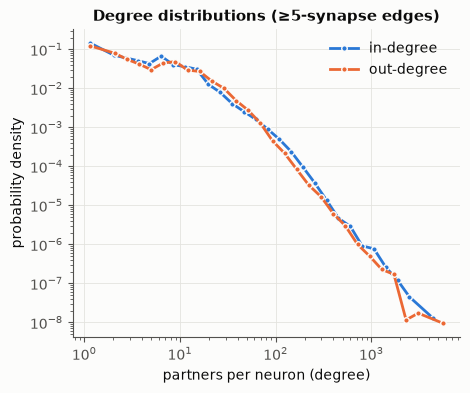

In [4]:
ax = gs.plot_degree_distributions(g)
ax.figure.savefig(FIGURES / "degree_distributions.png")
plt.show()

## Connection weights

How many synapses make up one neuron-to-neuron connection. The dashed line is the ≥5 threshold
applied in Phase 0, so the distribution starts there.

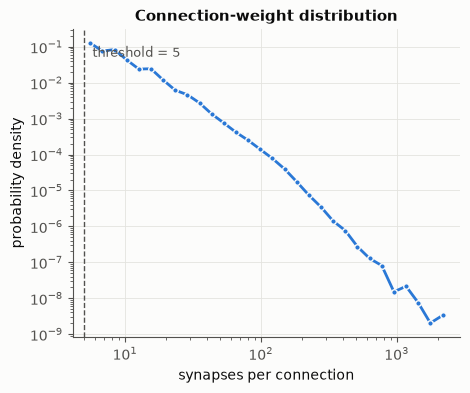

In [5]:
ax = gs.plot_weight_distribution(g, min_syn=5)
ax.figure.savefig(FIGURES / "weight_distribution.png")
plt.show()

## Region-to-region connectivity

Each neuron is assigned to its **home neuropil** (where it receives the most synapses); left and right
hemispheres are merged. Cell (a, b) = synapses from neurons homed in *a* onto neurons homed in *b*.
Regions are ordered by total synapses. The diagonal shows how much wiring stays local.

44 regions; 57.9% of synapses stay within a region


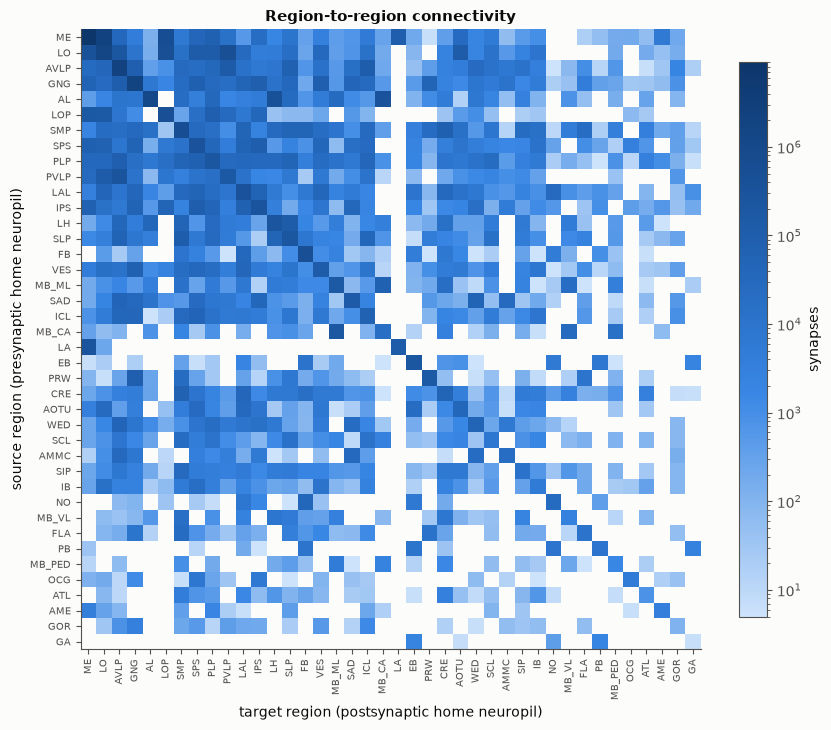

In [6]:
M, names = gs.neuropil_matrix(g, merge=True)
print(f"{len(names)} regions; {np.trace(M) / M.sum():.1%} of synapses stay within a region")

fig, ax = plt.subplots(figsize=(10, 9))
gs.plot_neuropil_heatmap(M, names, top=40, ax=ax)
fig.savefig(FIGURES / "neuropil_heatmap.png")
plt.show()

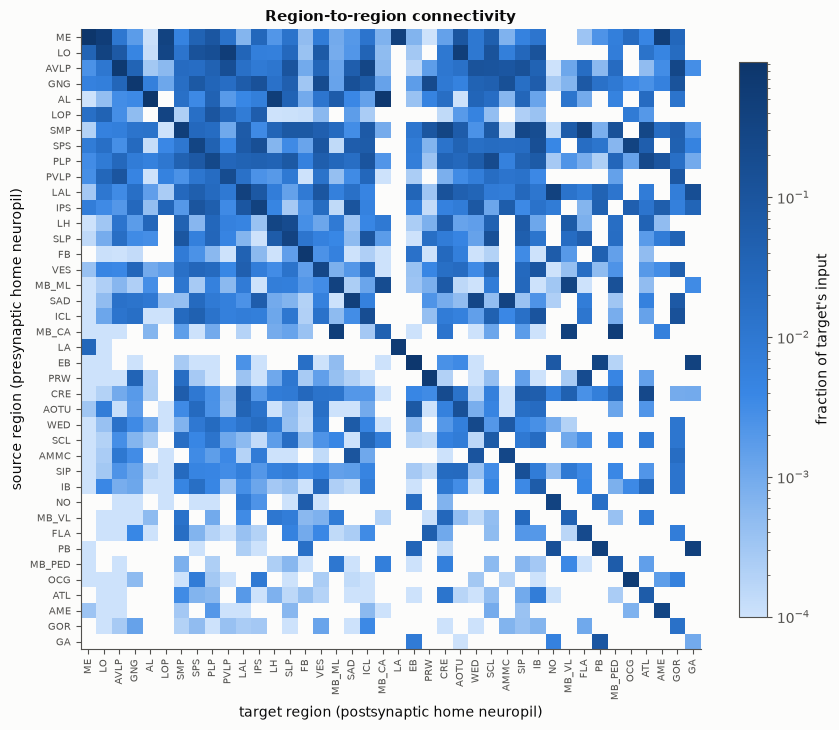

In [7]:
# Same matrix, each column normalised: where does a region's input come from?
fig, ax = plt.subplots(figsize=(10, 9))
gs.plot_neuropil_heatmap(M, names, top=40, normalize="target", ax=ax)
fig.savefig(FIGURES / "neuropil_heatmap_input_fraction.png")
plt.show()

## Excitation vs inhibition per region

Share of each region's **input** synapses that are excitatory (ACH), inhibitory (GABA, GLUT) or
modulatory (SER, DA, OCT), using the neurotransmitter predicted for the presynaptic neuron.

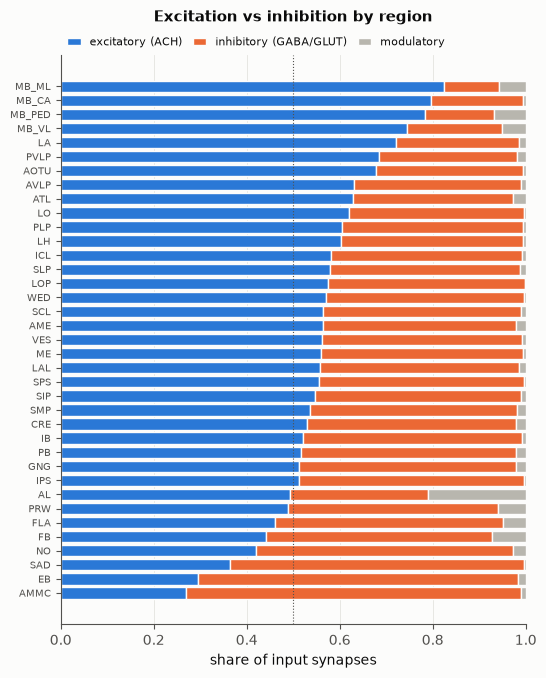

In [8]:
ei = gs.ei_share_by_region(g, merge=True)
ax = gs.plot_ei_share(ei, min_synapses=10_000)
ax.figure.savefig(FIGURES / "ei_share_by_region.png")
plt.show()

In [9]:
ei[["total", "excitatory_share", "inhibitory_share"]].round(3).head(10)

,total,excitatory_share,inhibitory_share
region,,,
BU,14,1.000,0.000
UNASGD,8,1.000,0.000
GA,6139,0.840,0.158
MB_ML,430656,0.825,0.117
MB_CA,398828,0.797,0.197
MB_PED,27845,0.784,0.149
MB_VL,67172,0.745,0.205
LA,219951,0.720,0.265
PVLP,966057,0.684,0.298


In [10]:
ei[["total", "excitatory_share", "inhibitory_share"]].round(3).tail(10)

,total,excitatory_share,inhibitory_share
region,,,
IPS,699491,0.512,0.484
AL,1170306,0.494,0.295
PRW,241972,0.488,0.451
FLA,52740,0.462,0.490
FB,663763,0.440,0.487
NO,75023,0.420,0.554
OCG,8357,0.373,0.447
SAD,322269,0.365,0.632
EB,290024,0.295,0.688


## Takeaways

- **Hubs are real.** The average neuron has ~20 strong input partners, but the most
  connected one has 5,080 inputs, and one neuron sends output to 6,399 others.
  Both degree distributions have heavy, roughly power-law tails.
- **Wiring is mostly local.** 57.9% of synapses connect neurons homed in the same region.
- **Regions differ sharply in E/I balance.** The mushroom body lobes are ~75–83% excitatory
  (its Kenyon cells are cholinergic), while the ellipsoid body (the fly's heading
  compass) is ~69% inhibitory, as are SAD and AMMC (antennal mechanosensory areas).
  The antennal lobe stands out with ~21% modulatory input.